# 01 · Calidad de datos (ETL) y análisis exploratorio — DataByte / RescateAlimento
**Capstone · Etapas 3 y 4 (preparar datos antes de modelar)**

## ¿Qué piden los apuntes y cómo se traduce a *nuestro* proyecto?
| Apunte de la clase | Qué hacemos en este notebook |
|---|---|
| §6 Calidad de datos: *no puede haber `NaN` en lo que entra al modelo* | Detectamos nulos, duplicados y outliers y los tratamos con reglas explícitas (mediana, moda, tope). |
| §1 Análisis exploratorio: heatmap de correlación, correlaciones **no lineales**, descartar variables que no aportan | Heatmaps Pearson y Spearman, gráficos de dispersión y *información mutua* (detecta relaciones no lineales). |
| §5 ROI "coherente con los datos reales" | Estimamos con los datos la **sensibilidad de las ventas al precio** y la **tasa de merma**; el notebook 03 las usa para simular el ROI. |

## ⚠️ Aviso importante sobre los datos
Hoy el bot **todavía no acumuló historial real de ventas** (la pestaña `Ventas_Registradas` nació en la v02.7).
Por eso este notebook trabaja con **datos SIMULADOS** (columna `fuente = "SIMULADO"`) generados con reglas realistas
(más ventas el fin de semana, el descuento sube las ventas, el stock limita lo que se puede vender, ruido aleatorio).

* Sirven para **construir y validar todo el pipeline** (limpieza → modelos → score → ROI).
* **No sirven para afirmar resultados reales** ante el jurado: los modelos aprenden las reglas del simulador.
* Cuando tengas datos reales, exportá la pestaña `Ventas_Registradas` como `data/Ventas_Registradas.csv`:
  la celda de abajo lo detecta sola y **todo el notebook corre con datos reales** sin tocar nada más.

## 0. Configuración

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42                                   # semilla fija: los resultados se pueden repetir
RUTA_REAL = "data/Ventas_Registradas.csv"   # export de la pestaña del Google Sheet (si existe)
USAR_DATOS_REALES = os.path.exists(RUTA_REAL)
print("Fuente de datos:", "REAL (Ventas_Registradas.csv)" if USAR_DATOS_REALES else "SIMULADA")

Fuente de datos: SIMULADA


## 1. Origen de los datos
Necesitamos un **panel diario**: una fila por *comercio × producto × día* con lo vendido ese día y el contexto
(precio propio, precio de la competencia, stock, días al vencimiento). Es lo que describe una decisión real:
*"con este precio y este stock, ¿cuánto voy a vender mañana?"*.

### 1.A Simulador (se usa si no hay datos reales)
Catálogo de 12 productos y 3 comercios de distinto tamaño. Reglas del simulador (todas razonables y modificables):
* **Día de la semana**: viernes y sábado venden más; los primeros días del mes (cobro de sueldos) también.
* **Precio**: la demanda sube cuando el precio baja respecto de la competencia (`exp(-e·(precio_rel-1))`).
* **Lotes**: cada lote tiene vencimiento; si no se vende todo, lo que sobra es **merma**.
* **Comportamiento del comerciante**: a veces rebaja cerca del vencimiento, a veces no (como pasa en la realidad).
* **Ruido**: las ventas son aleatorias (Poisson) y están limitadas por el stock disponible.

In [2]:
# Catálogo: precio_lista = precio de la competencia (lo que hoy trae n8n), costo, vida útil, demanda base (un/día
# en un comercio mediano) y e = sensibilidad al precio usada SOLO por el simulador.
PRODUCTOS = pd.DataFrame([
    # ean,             producto,                    marca,    categoria,    pref, costo, vida, base, e
    ("7790360026578", "Hamburguesas Swift 4 Un",   "SWIFT",  "Congelados", 7890, 5200, 45,  5, 2.0),
    ("7790670050674", "Hamburguesas Paty 2 Un",    "PATY",   "Congelados", 2500, 1700, 45,  8, 2.0),
    ("7790000000011", "Milanesas de Pollo 1 kg",   "GRANJA", "Congelados", 6200, 4300, 40,  4, 1.8),
    ("7790000000028", "Yogur Entero 1 L",          "LACTEA", "Lacteos",    2100, 1400, 18,  9, 1.6),
    ("7790000000035", "Queso Cremoso 500 g",       "LACTEA", "Lacteos",    4800, 3300, 20,  4, 1.7),
    ("7790000000042", "Leche Entera 1 L",          "LACTEA", "Lacteos",    1500, 1100, 12, 14, 1.2),
    ("7790000000059", "Jamon Cocido 200 g",        "FIAMBR", "Fiambres",   3900, 2700, 22,  5, 1.9),
    ("7790000000066", "Salchichas x6",             "FIAMBR", "Fiambres",   2400, 1600, 25,  6, 1.8),
    ("7790000000073", "Pan Lactal 500 g",          "PANIFI", "Panificados",2800, 1900,  7, 10, 2.2),
    ("7790000000080", "Medialunas x6",             "PANIFI", "Panificados",3300, 2200,  5,  7, 2.5),
    ("7790000000097", "Pollo Entero kg",           "FRESCO", "Frescos",    3900, 2900,  8,  6, 2.0),
    ("7790000000103", "Gaseosa 2.25 L",            "BEBIDA", "Bebidas",    2700, 1900, 90, 10, 1.0),
], columns=["ean","producto","marca","categoria","precio_lista","costo","vida_util","base","e"])

COMERCIOS = {"1001": 1.5, "1002": 1.0, "1003": 0.6}     # telegram_id -> tamaño relativo
FACTOR_DIA = {0: .90, 1: .90, 2: .95, 3: 1.00, 4: 1.25, 5: 1.35, 6: 1.10}   # lunes..domingo

def simular_panel(seed=SEED, dias=120, fin="2026-11-15"):
    # Devuelve (panel diario, tabla de lotes). Cada día de cada comercio-producto es una fila.
    rng = np.random.default_rng(seed)
    fechas = pd.date_range(end=fin, periods=dias, freq="D")
    filas, lotes, n = [], [], 0
    for tid, tam in COMERCIOS.items():
        for _, p in PRODUCTOS.iterrows():
            lote = None
            for f in fechas:
                # Se repone cuando no hay lote, se agotó o ya venció (sin días sin stock: panel continuo).
                if lote is None or lote["stock"] <= 0 or f > lote["venc"]:
                    if lote is not None:
                        lote["merma"] = lote["stock"] if f > lote["venc"] else 0
                        lote["cerrado"] = True; lotes.append(lote)
                    n += 1
                    vida = int(p.vida_util - rng.integers(0, 4))
                    cant = max(5, int(p.base * tam * min(p.vida_util, 30) * rng.uniform(0.8, 1.5)))
                    lote = dict(id_lote=f"LOT-{n:05d}", telegram_id=tid, ean=p.ean, producto=p.producto,
                                cantidad_inicial=cant, stock=cant, ingreso=f, venc=f + pd.Timedelta(days=vida),
                                precio_base=p.precio_lista * rng.uniform(0.93, 1.06), costo=p.costo,
                                agresividad=float(rng.choice([0, 0, .1, .2, .3])), vendidas=0, cerrado=False)
                dias_rest = (lote["venc"] - f).days
                pref = p.precio_lista * (1 + rng.normal(0, .015))                  # precio de la competencia hoy
                precio = lote["precio_base"] * (1 - lote["agresividad"] if dias_rest <= 5 else 1)
                rel = precio / pref
                lam = (p.base * tam * FACTOR_DIA[f.dayofweek] * (1.15 if f.day <= 5 else 1.0)
                       * np.exp(-p.e * (rel - 1)) * rng.lognormal(0, .15))
                vendidas = int(min(rng.poisson(lam), lote["stock"]))
                filas.append(dict(fecha=f, telegram_id=tid, ean=p.ean, producto=p.producto, marca=p.marca,
                                  categoria=p.categoria, id_lote=lote["id_lote"], precio_venta=round(precio, 2),
                                  precio_competencia=round(pref, 2), stock_inicial_dia=lote["stock"],
                                  dias_al_vencimiento=dias_rest, unidades_vendidas=vendidas))
                lote["stock"] -= vendidas; lote["vendidas"] += vendidas
            lote["merma"] = 0; lote["cerrado"] = False; lotes.append(lote)         # lote abierto al final
    panel = pd.DataFrame(filas)
    tabla = pd.DataFrame(lotes).drop(columns=["stock"]).rename(columns={"venc": "fecha_vencimiento", "ingreso": "fecha_ingreso"})
    return panel, tabla

def panel_desde_real(ruta):
    # Arma el mismo panel desde la pestaña Ventas_Registradas (una fila por lote vendido en cada carga).
    # Limitación: esa pestaña no trae stock, precio de la competencia ni vencimiento; quedan como NaN y los
    # imputa la sección de limpieza (o se pueden unir con Lotes_Registrados y el catálogo).
    v = pd.read_csv(ruta, dtype={"telegram_id": str, "ean": str})
    v["fecha"] = pd.to_datetime(v["fecha_vendido"].fillna(v["fecha_hora"]), dayfirst=True, errors="coerce").dt.normalize()
    v = v.dropna(subset=["fecha"])
    g = (v.groupby(["telegram_id", "ean", "fecha"])
           .agg(producto=("producto", "first"), marca=("marca", "first"),
                precio_venta=("precio_unidad", "mean"), unidades_vendidas=("cantidad_unitarias", "sum"),
                id_lote=("id_lote", "last")).reset_index())
    partes = []
    for (t, e), s in g.groupby(["telegram_id", "ean"]):        # días sin venta = 0 unidades (no "dato faltante")
        s = s.set_index("fecha").reindex(pd.date_range(s["fecha"].min(), s["fecha"].max()))
        s["unidades_vendidas"] = s["unidades_vendidas"].fillna(0)
        s[["telegram_id", "ean", "producto", "marca", "id_lote"]] = s[["telegram_id", "ean", "producto", "marca", "id_lote"]].ffill().bfill()
        s["fecha"] = s.index; partes.append(s.reset_index(drop=True))
    p = pd.concat(partes, ignore_index=True)
    for c in ["categoria", "precio_competencia", "stock_inicial_dia", "dias_al_vencimiento"]:
        p[c] = np.nan
    return p, pd.DataFrame()

if USAR_DATOS_REALES:
    panel, tabla_lotes = panel_desde_real(RUTA_REAL)
else:
    panel, tabla_lotes = simular_panel()
panel["fuente"] = "REAL" if USAR_DATOS_REALES else "SIMULADO"
print(f"Panel: {len(panel):,} filas · {panel.telegram_id.nunique()} comercios · {panel.ean.nunique()} productos · "
      f"{panel.fecha.min():%d/%m/%Y} → {panel.fecha.max():%d/%m/%Y}")
panel.head()

Panel: 4,320 filas · 3 comercios · 12 productos · 19/07/2026 → 15/11/2026


,fecha,telegram_id,ean,producto,marca,categoria,id_lote,precio_venta,precio_competencia,stock_inicial_dia,dias_al_vencimiento,unidades_vendidas,fuente
0,2026-07-19,1001,7790360026578,Hamburguesas Swift 4 Un,SWIFT,Congelados,LOT-00001,8218.36,8001.32,249,45,9,SIMULADO
1,2026-07-20,1001,7790360026578,Hamburguesas Swift 4 Un,SWIFT,Congelados,LOT-00001,8218.36,7788.30,240,44,8,SIMULADO
2,2026-07-21,1001,7790360026578,Hamburguesas Swift 4 Un,SWIFT,Congelados,LOT-00001,8218.36,7953.00,232,43,7,SIMULADO
3,2026-07-22,1001,7790360026578,Hamburguesas Swift 4 Un,SWIFT,Congelados,LOT-00001,8218.36,7876.51,225,42,8,SIMULADO
4,2026-07-23,1001,7790360026578,Hamburguesas Swift 4 Un,SWIFT,Congelados,LOT-00001,8218.36,7915.88,217,41,2,SIMULADO


### 1.B Ensuciamos los datos a propósito (solo en modo simulado)
Los datos reales **siempre** vienen con problemas (el comerciante se olvida un campo, el catálogo no tiene un EAN,
el cuaderno se transcribe mal...). Para practicar la limpieza que piden los apuntes, inyectamos problemas típicos:
nulos, duplicados, un error de tipeo (×20) y valores negativos imposibles.

In [3]:
crudo = panel.copy()
if not USAR_DATOS_REALES:
    rng = np.random.default_rng(SEED + 1)
    n = len(crudo)
    crudo.loc[rng.choice(n, int(.05 * n), replace=False), "precio_competencia"] = np.nan   # EAN sin dato de competencia
    crudo.loc[rng.choice(n, int(.01 * n), replace=False), "precio_venta"] = np.nan          # precio no cargado
    crudo.loc[rng.choice(n, int(.005 * n), replace=False), "unidades_vendidas"] = np.nan    # venta ilegible en el cuaderno
    crudo.loc[rng.choice(n, int(.02 * n), replace=False), "categoria"] = np.nan             # producto sin categoría
    ruido = rng.choice(n, 5, replace=False)
    crudo.loc[ruido, "unidades_vendidas"] = crudo.loc[ruido, "unidades_vendidas"].fillna(1) * 20   # error de tipeo
    crudo.loc[rng.choice(n, 8, replace=False), "unidades_vendidas"] = -3                    # negativos imposibles
    crudo = pd.concat([crudo, crudo.sample(25, random_state=SEED)], ignore_index=True)       # cargas duplicadas
crudo.to_csv("data/ventas_crudas.csv", index=False)
print("Guardado: data/ventas_crudas.csv", crudo.shape)

Guardado: data/ventas_crudas.csv (4345, 13)


## 2. Calidad de datos (ETL) — la regla de oro: *ningún `NaN` entra al modelo*
Primero **medimos** el problema, después aplicamos **una regla por tipo de variable** (la de los apuntes):
| Problema | Regla aplicada | Por qué |
|---|---|---|
| Filas duplicadas | `drop_duplicates` | una carga repetida contaría ventas dos veces |
| Valores imposibles (unidades < 0) | se marcan como nulo y se imputan | no existe una venta negativa |
| Numéricos nulos | **mediana** del mismo producto (y comercio) | la mediana no se contamina con extremos |
| Categóricos nulos | **moda** del mismo producto | la categoría de un EAN no cambia |
| Outliers (error de tipeo) | **tope** en Q3 + 3·IQR del mismo comercio-producto | conserva la fila pero evita que un ×20 distorsione el modelo |

In [4]:
def diagnostico(df):
    t = pd.DataFrame({"nulos": df.isna().sum(), "% nulos": (df.isna().mean() * 100).round(2)})
    return t[t.nulos > 0]

print("Filas duplicadas:", crudo.duplicated().sum())
print("Unidades negativas:", (crudo.unidades_vendidas < 0).sum())
print("\nNulos ANTES de limpiar:")
diagnostico(crudo)

Filas duplicadas: 25
Unidades negativas: 8

Nulos ANTES de limpiar:


,nulos,% nulos
categoria,86,1.98
precio_venta,43,0.99
precio_competencia,218,5.02
unidades_vendidas,20,0.46


In [5]:
def limpiar(df):
    d = df.drop_duplicates().copy()
    d.loc[d.unidades_vendidas < 0, "unidades_vendidas"] = np.nan                  # imposibles -> nulo

    # Numéricos: mediana del mismo producto y comercio; si aún falta, mediana del producto; si no, la global.
    for col, claves in [("unidades_vendidas", ["telegram_id", "ean"]),
                        ("precio_venta", ["telegram_id", "ean"]),
                        ("precio_competencia", ["ean"]),
                        ("stock_inicial_dia", ["telegram_id", "ean"]),
                        ("dias_al_vencimiento", ["ean"])]:
        if d[col].isna().all():
            # Con datos reales, Ventas_Registradas no trae estas columnas: se usa un valor de respaldo CONSTANTE
            # (la variable queda sin poder predictivo hasta unir Lotes_Registrados y el catálogo de la competencia).
            respaldo = {"precio_competencia": d["precio_venta"],
                        "stock_inicial_dia": d.groupby(["telegram_id", "ean"])["unidades_vendidas"].transform("mean") * 10,
                        "dias_al_vencimiento": 30.0}
            d[col] = respaldo[col]
            print(f"⚠️ '{col}' no viene en los datos: se usa un valor de respaldo.")
        d[col] = d[col].fillna(d.groupby(claves)[col].transform("median")).fillna(d.groupby("ean")[col].transform("median"))
        d[col] = d[col].fillna(d[col].median())

    # Categórico: moda por producto.
    moda = d.groupby("ean")["categoria"].agg(lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
    d["categoria"] = d["categoria"].fillna(d["ean"].map(moda)).fillna("Sin categoria")

    # Outliers: tope superior por serie (comercio-producto).
    q1 = d.groupby(["telegram_id", "ean"])["unidades_vendidas"].transform(lambda s: s.quantile(.25))
    q3 = d.groupby(["telegram_id", "ean"])["unidades_vendidas"].transform(lambda s: s.quantile(.75))
    tope = q3 + 3 * (q3 - q1)
    d["outlier_corregido"] = d.unidades_vendidas > tope
    d["unidades_vendidas"] = np.minimum(d.unidades_vendidas, tope)
    return d

limpio = limpiar(crudo)
print("Filas: antes", len(crudo), "→ después", len(limpio))
print("Outliers topeados:", int(limpio.outlier_corregido.sum()))
assert limpio.drop(columns=["outlier_corregido"]).isna().sum().sum() == 0, "Quedaron NaN"
print("✅ Cero NaN en los datos limpios")
limpio.to_csv("data/ventas_limpias.csv", index=False)

Filas: antes 4345 → después 4320
Outliers topeados: 8
✅ Cero NaN en los datos limpios


## 3. Variables nuevas (*feature engineering*)
Un modelo no ve "fechas": hay que convertirlas en señales. Las más importantes en demanda minorista:
* **Calendario**: día de la semana, fin de semana, día del mes.
* **Precio relativo** = `precio_venta / precio_competencia` ← **es la variable de inteligencia competitiva**: dice si estamos más caros o más baratos que el mercado. `1.0` = igual; `0.7` = 30 % más barato.
* **Memoria de ventas** (*lags* y medias móviles): ayer, hace 7 días, media de 7 y de 28 días.
  Se calculan con `shift(1)` para usar **solo información disponible antes del día a predecir** (si no, el modelo "espía el futuro" — *data leakage*).
* Las primeras 28 filas de cada serie no tienen historia suficiente: se **descartan** (no se rellenan con inventos).

In [6]:
d = limpio.sort_values(["telegram_id", "ean", "fecha"]).reset_index(drop=True)
d["fecha"] = pd.to_datetime(d["fecha"])
g = d.groupby(["telegram_id", "ean"])["unidades_vendidas"]

d["precio_rel"]     = d.precio_venta / d.precio_competencia
d["descuento_pct"]  = (1 - d.precio_rel) * 100
d["dow"]            = d.fecha.dt.dayofweek
d["es_finde"]       = d.dow.isin([4, 5, 6]).astype(int)            # vie-sáb-dom concentran las ventas
d["dia_mes"]        = d.fecha.dt.day
d["ventas_lag1"]    = g.shift(1)
d["ventas_lag7"]    = g.shift(7)
d["media_movil_7"]  = g.transform(lambda s: s.shift(1).rolling(7).mean())    # = el "ritmo" actual del Score
d["media_movil_28"] = g.transform(lambda s: s.shift(1).rolling(28).mean())

dataset = d.dropna(subset=["media_movil_28"]).reset_index(drop=True)
print(f"Dataset de modelado: {len(dataset):,} filas (se descartaron {len(d)-len(dataset)} sin historia suficiente)")
assert dataset[["precio_rel","ventas_lag1","ventas_lag7","media_movil_7","media_movil_28"]].isna().sum().sum() == 0
dataset.to_csv("data/dataset_modelado.csv", index=False)
dataset.head()

Dataset de modelado: 3,312 filas (se descartaron 1008 sin historia suficiente)


,fecha,telegram_id,ean,producto,marca,categoria,id_lote,precio_venta,precio_competencia,stock_inicial_dia,dias_al_vencimiento,unidades_vendidas,fuente,outlier_corregido,precio_rel,descuento_pct,dow,es_finde,dia_mes,ventas_lag1,ventas_lag7,media_movil_7,media_movil_28
0,2026-08-16,1001,7790000000011,Milanesas de Pollo 1 kg,GRANJA,Congelados,LOT-00011,5911.79,6209.51,15,9,3.0,SIMULADO,False,0.952054,4.794581,6,1,16,11.0,5.0,6.571429,6.607143
1,2026-08-17,1001,7790000000011,Milanesas de Pollo 1 kg,GRANJA,Congelados,LOT-00011,5911.79,6234.08,12,8,9.0,SIMULADO,False,0.948302,5.169809,0,0,17,3.0,5.0,6.285714,6.714286
2,2026-08-18,1001,7790000000011,Milanesas de Pollo 1 kg,GRANJA,Congelados,LOT-00011,5911.79,6289.70,3,7,3.0,SIMULADO,False,0.939916,6.008395,1,0,18,9.0,4.0,6.857143,6.928571
3,2026-08-19,1001,7790000000011,Milanesas de Pollo 1 kg,GRANJA,Congelados,LOT-00012,5792.44,6146.65,178,37,4.0,SIMULADO,False,0.942373,5.762651,2,0,19,3.0,6.0,6.714286,6.785714
4,2026-08-20,1001,7790000000011,Milanesas de Pollo 1 kg,GRANJA,Congelados,LOT-00012,5792.44,6236.00,174,36,13.0,SIMULADO,False,0.928871,7.112893,3,0,20,4.0,10.0,6.428571,6.571429


## 4. Análisis exploratorio
### 4.1 ¿Cuándo se vende? (estacionalidad semanal)

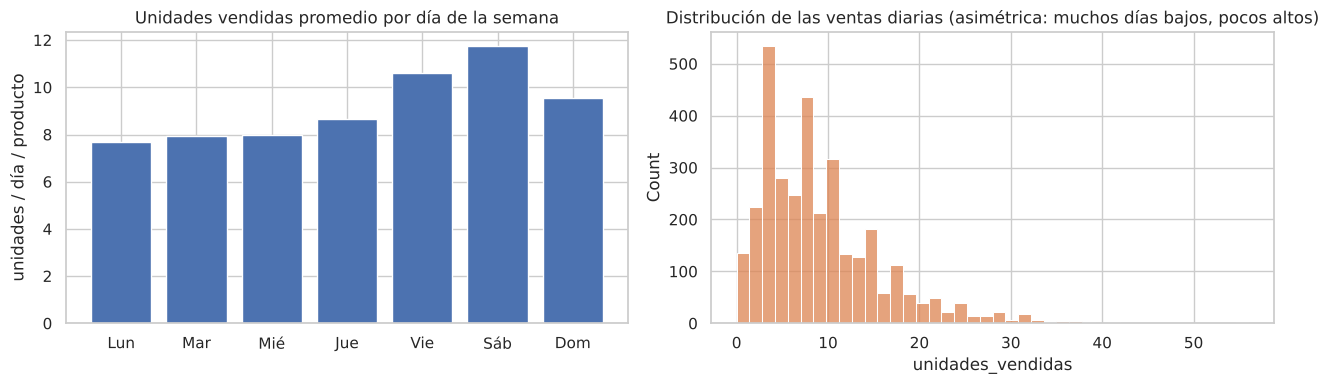

Viernes/Sábado venden 1.43× lo que Lun/Mar → el modelo necesita saber el día.


In [7]:
nombres = ["Lun","Mar","Mié","Jue","Vie","Sáb","Dom"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
dow = dataset.groupby("dow").unidades_vendidas.mean()
ax[0].bar(nombres, dow.values, color=sns.color_palette("deep")[0]); ax[0].set_title("Unidades vendidas promedio por día de la semana")
ax[0].set_ylabel("unidades / día / producto")
sns.histplot(dataset.unidades_vendidas, bins=40, ax=ax[1], color=sns.color_palette("deep")[1])
ax[1].set_title("Distribución de las ventas diarias (asimétrica: muchos días bajos, pocos altos)")
plt.tight_layout(); plt.show()
print(f"Viernes/Sábado venden {dow[[4,5]].mean()/dow[[0,1]].mean():.2f}× lo que Lun/Mar → el modelo necesita saber el día.")

### 4.2 Mapa de correlación (heatmap)
Resume en una imagen qué variables se mueven juntas.
* **Pearson** mide relación **lineal**. 
* **Spearman** mide relación **monótona** (sirve cuando la curva no es recta, p. ej. precio → ventas).
Lo que importa: la fila/columna de `unidades_vendidas`. Dos variables **muy parecidas entre sí** (|r| > 0.9) son redundantes: nos quedamos con una.

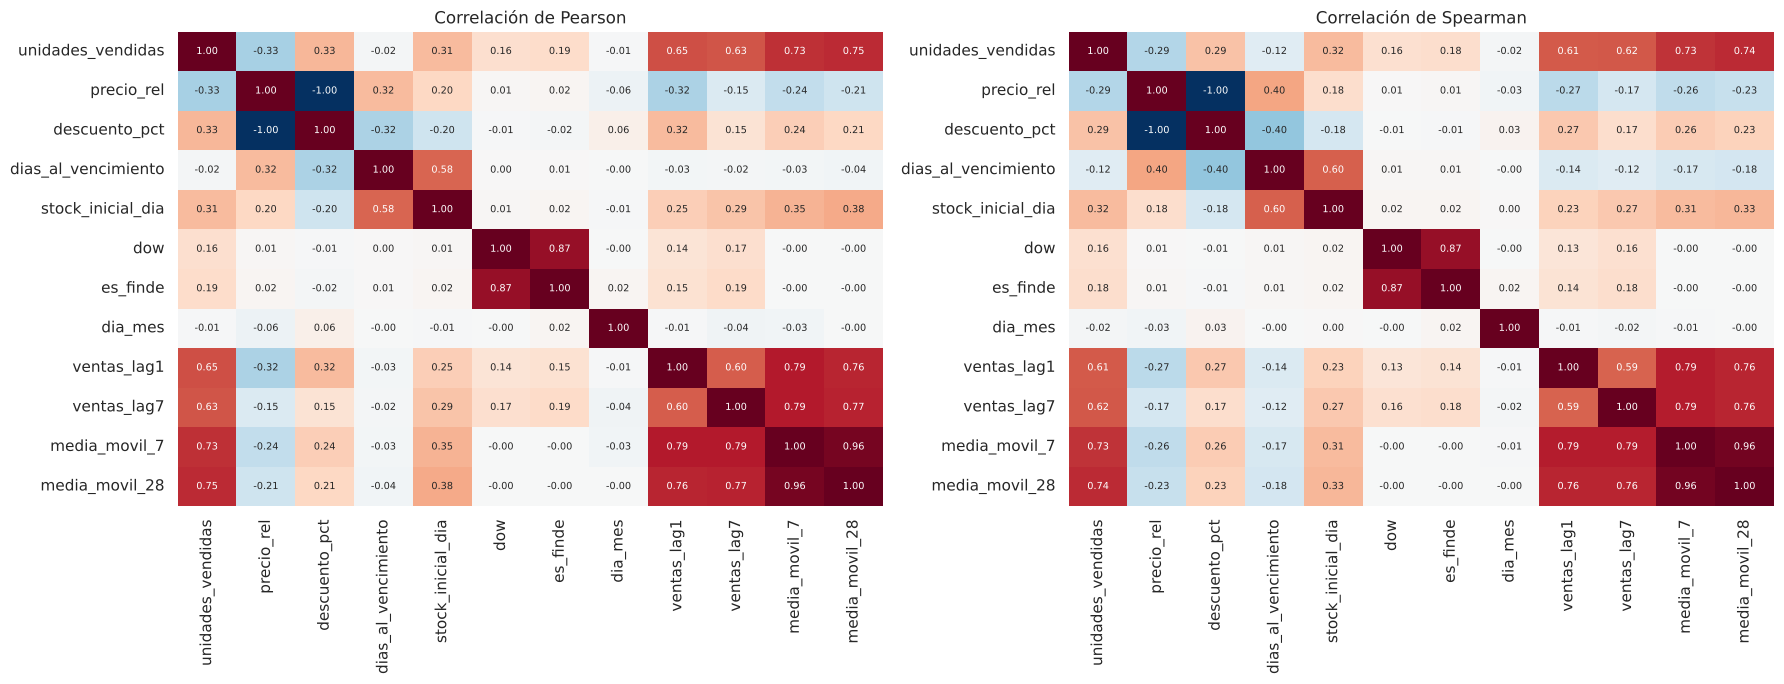

Correlación (Spearman) con las ventas:
 media_movil_28         0.743
media_movil_7          0.726
ventas_lag7            0.618
ventas_lag1            0.615
stock_inicial_dia      0.320
precio_rel            -0.291
descuento_pct          0.291
es_finde               0.176
dow                    0.157
dias_al_vencimiento   -0.121
dia_mes               -0.018

Redundancia: corr(precio_rel, descuento_pct) = -1.0 → son la MISMA información; se usa solo precio_rel.


In [8]:
NUM = ["unidades_vendidas","precio_rel","descuento_pct","dias_al_vencimiento","stock_inicial_dia",
       "dow","es_finde","dia_mes","ventas_lag1","ventas_lag7","media_movil_7","media_movil_28"]
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
for a, met in zip(ax, ["pearson", "spearman"]):
    sns.heatmap(dataset[NUM].corr(method=met), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                cbar=False, annot_kws={"size": 7}, ax=a)
    a.set_title(f"Correlación de {met.capitalize()}")
plt.tight_layout(); plt.show()

corr = dataset[NUM].corr(method="spearman")["unidades_vendidas"].drop("unidades_vendidas").sort_values(key=abs, ascending=False)
print("Correlación (Spearman) con las ventas:\n", corr.round(3).to_string())
print("\nRedundancia: corr(precio_rel, descuento_pct) =", round(dataset.precio_rel.corr(dataset.descuento_pct), 3),
      "→ son la MISMA información; se usa solo precio_rel.")

### 4.3 Relaciones no lineales: gráficos de dispersión
Un coeficiente de correlación puede engañar. Mirando la nube de puntos se ve rápido qué variable aporta
(una **recta plana** = "la nada misma": la variable no explica nada) y cuáles tienen curvas.

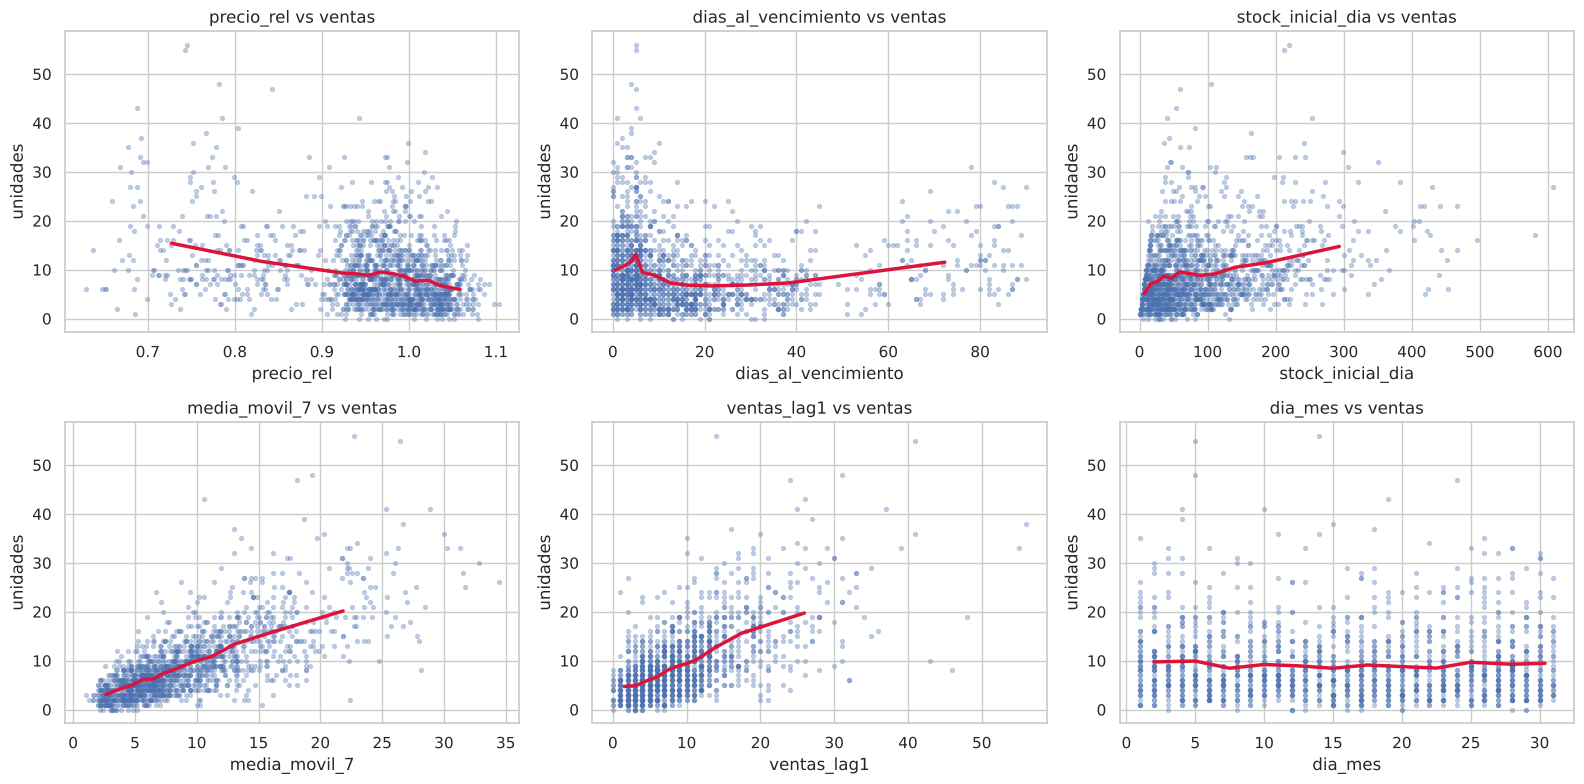

In [9]:
vars_plot = ["precio_rel","dias_al_vencimiento","stock_inicial_dia","media_movil_7","ventas_lag1","dia_mes"]
muestra = dataset.sample(min(1500, len(dataset)), random_state=SEED)
fig, axs = plt.subplots(2, 3, figsize=(16, 8))
for a, v in zip(axs.ravel(), vars_plot):
    a.scatter(muestra[v], muestra.unidades_vendidas, s=8, alpha=.3)
    # Curva roja = promedio de ventas por tramos de la variable (muestra la forma real de la relación).
    tramos = pd.qcut(dataset[v], q=12, duplicates="drop")
    curva = dataset.groupby(tramos, observed=True).agg(x=(v, "mean"), y=("unidades_vendidas", "mean"))
    a.plot(curva.x, curva.y, color="crimson", lw=2.5)
    a.set_title(f"{v} vs ventas"); a.set_xlabel(v); a.set_ylabel("unidades")
plt.tight_layout(); plt.show()

### 4.4 Información mutua (detecta relaciones no lineales sin mirar gráficos)
La **información mutua** (MI) vale 0 si la variable no dice nada sobre las ventas y crece cuando sí. A diferencia de
la correlación, **detecta curvas y escalones**. Es el equivalente numérico del "panel de correlaciones no lineales" que
mencionan los apuntes. *(Advertencia de los apuntes: usar el criterio visual con cabeza, no como único filtro.)*

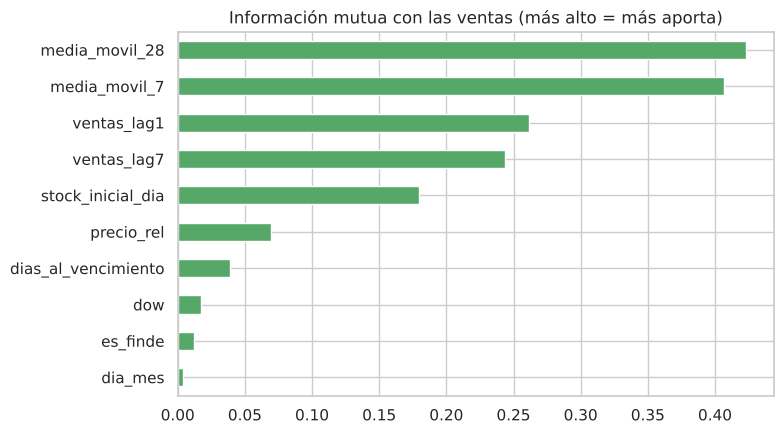

media_movil_28         0.423
media_movil_7          0.407
ventas_lag1            0.262
ventas_lag7            0.244
stock_inicial_dia      0.180
precio_rel             0.069
dias_al_vencimiento    0.039
dow                    0.017
es_finde               0.012
dia_mes                0.004
dtype: float64

In [10]:
CANDIDATAS = ["precio_rel","dias_al_vencimiento","stock_inicial_dia","dow","es_finde","dia_mes",
              "ventas_lag1","ventas_lag7","media_movil_7","media_movil_28"]
mi = mutual_info_regression(dataset[CANDIDATAS], dataset.unidades_vendidas, random_state=SEED)
mi = pd.Series(mi, index=CANDIDATAS).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
mi.plot.barh(ax=ax, color=sns.color_palette("deep")[2]); ax.set_title("Información mutua con las ventas (más alto = más aporta)")
plt.tight_layout(); plt.show()
mi.sort_values(ascending=False).round(3)

### 4.5 Decisión: ¿qué variables entran al modelo?
| Variable | Decisión | Motivo |
|---|---|---|
| `media_movil_7`, `media_movil_28`, `ventas_lag1`, `ventas_lag7` | ✅ entran | Memoria de la demanda: lo que mejor predice (y la media móvil 7 es el "ritmo" que usa hoy el Score). |
| `precio_rel` | ✅ entra | Inteligencia competitiva: relación **no lineal** con las ventas. |
| `dow`, `es_finde`, `dia_mes` | ✅ entran | Estacionalidad semanal y de cobro de sueldos. |
| `stock_inicial_dia` | ✅ entra | Limita lo que se puede vender (si hay 3 unidades no se venden 10). |
| `dias_al_vencimiento` | ✅ entra | Relación con el descuento y con el comportamiento del comerciante. |
| `descuento_pct` | ❌ se descarta | Es `100·(1 − precio_rel)`: información duplicada. |
| `categoria`, `ean`, `telegram_id` | ✅ entran como categóricas | Cada producto/comercio tiene su nivel de demanda. |

## 5. Parámetros del negocio estimados con los datos (los usa el notebook 03)
### 5.1 Sensibilidad de las ventas al precio
Ajustamos `log(ventas + 1) = a + b · log(precio_rel) + efectos de día`. El coeficiente `b` (en negativo) es
*"si el precio baja 10 %, las ventas suben ≈ −b·10 %"*. Es la pieza que hace **coherente** la simulación del ROI con los datos.
### 5.2 Tasa de merma observada
`merma = unidades que vencieron sin venderse / unidades ingresadas` (solo lotes ya cerrados). Es la **línea base**: el ROI
se mide contra este número.

In [11]:
X = pd.DataFrame({"log_precio_rel": np.log(dataset.precio_rel)})
X = pd.concat([X, pd.get_dummies(dataset.dow, prefix="dow", drop_first=True).astype(float)], axis=1)
y = np.log1p(dataset.unidades_vendidas)
lr = LinearRegression().fit(X, y)
sensibilidad = float(-lr.coef_[0])
print(f"Sensibilidad al precio estimada: {sensibilidad:.2f}  → bajar el precio 10 % ≈ +{(1.1**sensibilidad-1)*100:.0f} % de ventas")

if len(tabla_lotes):
    cerrados = tabla_lotes[tabla_lotes.cerrado]
    tasa_merma = float(cerrados.merma.sum() / cerrados.cantidad_inicial.sum())
    meses = (panel.fecha.max() - panel.fecha.min()).days / 30.4
    lotes_mes_por_comercio = float(len(cerrados) / meses / panel.telegram_id.nunique())
    print(f"Merma observada: {tasa_merma:.1%} de las unidades ingresadas ({int(cerrados.merma.sum()):,} de {int(cerrados.cantidad_inicial.sum()):,})")
    print(f"Lotes por mes por comercio: {lotes_mes_por_comercio:.1f}")
    resumen = (cerrados.groupby("producto").agg(lotes=("id_lote","count"), merma_pct=("merma", "sum"), ingresadas=("cantidad_inicial","sum")))
    resumen["merma_pct"] = (resumen.merma_pct / resumen.ingresadas * 100).round(1)
    display(resumen.sort_values("merma_pct", ascending=False)[["lotes","merma_pct"]])
    tabla_lotes.to_csv("data/lotes_simulados.csv", index=False)
else:
    tasa_merma, lotes_mes_por_comercio = None, None
    print("Con datos reales: calcular la merma desde Lotes_Registrados (cantidad restante de lotes vencidos).")

with open("data/parametros.json", "w") as f:
    json.dump({"fuente": "REAL" if USAR_DATOS_REALES else "SIMULADO", "sensibilidad_precio": sensibilidad,
               "tasa_merma_observada": tasa_merma, "lotes_mes_por_comercio": lotes_mes_por_comercio}, f, indent=2)
print("Guardado: data/parametros.json")

Sensibilidad al precio estimada: 1.99  → bajar el precio 10 % ≈ +21 % de ventas
Merma observada: 6.1% de las unidades ingresadas (2,377 de 38,892)
Lotes por mes por comercio: 31.0


,lotes,merma_pct
producto,,
Medialunas x6,98,12.7
Leche Entera 1 L,32,10.9
Salchichas x6,15,7.1
Pan Lactal 500 g,64,6.8
Queso Cremoso 500 g,19,6.5
Pollo Entero kg,54,6.4
Jamon Cocido 200 g,17,5.6
Yogur Entero 1 L,22,5.0
Hamburguesas Swift 4 Un,11,0.0


Guardado: data/parametros.json


## 6. Conclusiones de este notebook
1. **Calidad**: pasamos de datos con nulos, duplicados, negativos y un error de tipeo a un dataset con **cero `NaN`**, con cada regla documentada (así se puede defender ante el jurado y repetir con datos reales).
2. **Qué explica las ventas**: la **memoria reciente** (medias móviles/lags), el **día de la semana** y el **precio relativo a la competencia**. Los dos primeros ya los usa el Score; el tercero es nuestro diferencial de inteligencia competitiva.
3. **Línea base de negocio**: la merma observada y la sensibilidad al precio quedan guardadas para calcular el ROI (notebook 03).
4. **Siguiente paso**: `02_Modelos_de_demanda.ipynb` prueba los 5 modelos que recomiendan los apuntes y los compara contra la heurística actual.

> Para pasar a datos reales: exportá `Ventas_Registradas` a `data/Ventas_Registradas.csv` y volvé a ejecutar los 3 notebooks en orden.